In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
df = pd.read_csv("co2.csv")

In [ ]:
df

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244
...,...,...,...,...,...,...,...,...,...,...,...,...
7380,VOLVO,XC40 T5 AWD,SUV - SMALL,2.0,4,AS8,Z,10.7,7.7,9.4,30,219
7381,VOLVO,XC60 T5 AWD,SUV - SMALL,2.0,4,AS8,Z,11.2,8.3,9.9,29,232
7382,VOLVO,XC60 T6 AWD,SUV - SMALL,2.0,4,AS8,Z,11.7,8.6,10.3,27,240
7383,VOLVO,XC90 T5 AWD,SUV - STANDARD,2.0,4,AS8,Z,11.2,8.3,9.9,29,232


#Data Cleaning

In [ ]:
#Missing Value
df.isna().sum()

,0
Make,0
Model,0
Vehicle Class,0
Engine Size(L),0
Cylinders,0
Transmission,0
Fuel Type,0
Fuel Consumption City (L/100 km),0
Fuel Consumption Hwy (L/100 km),0
Fuel Consumption Comb (L/100 km),0


In [ ]:
#Check if there duplicates
print("How many duplicates : ", df.duplicated().sum())

How many duplicates :  1103


In [ ]:
#Drop the duplicates
df = df.drop_duplicates()

In [ ]:
#Check Unique Value
df.nunique().sort_values()

,0
Fuel Type,5
Cylinders,8
Vehicle Class,16
Transmission,27
Make,42
Engine Size(L),51
Fuel Consumption Comb (mpg),54
Fuel Consumption Hwy (L/100 km),143
Fuel Consumption Comb (L/100 km),181
Fuel Consumption City (L/100 km),211


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6282 entries, 0 to 7384
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Make                              6282 non-null   object 
 1   Model                             6282 non-null   object 
 2   Vehicle Class                     6282 non-null   object 
 3   Engine Size(L)                    6282 non-null   float64
 4   Cylinders                         6282 non-null   int64  
 5   Transmission                      6282 non-null   object 
 6   Fuel Type                         6282 non-null   object 
 7   Fuel Consumption City (L/100 km)  6282 non-null   float64
 8   Fuel Consumption Hwy (L/100 km)   6282 non-null   float64
 9   Fuel Consumption Comb (L/100 km)  6282 non-null   float64
 10  Fuel Consumption Comb (mpg)       6282 non-null   int64  
 11  CO2 Emissions(g/km)               6282 non-null   int64  
dtypes: float64(

#EDA

In [ ]:
print(df.describe())

       Engine Size(L)    Cylinders  Fuel Consumption City (L/100 km)  \
count     6282.000000  6282.000000                       6282.000000   
mean         3.161812     5.618911                         12.610220   
std          1.365201     1.846250                          3.553066   
min          0.900000     3.000000                          4.200000   
25%          2.000000     4.000000                         10.100000   
50%          3.000000     6.000000                         12.100000   
75%          3.700000     6.000000                         14.700000   
max          8.400000    16.000000                         30.600000   

       Fuel Consumption Hwy (L/100 km)  Fuel Consumption Comb (L/100 km)  \
count                      6282.000000                       6282.000000   
mean                          9.070583                         11.017876   
std                           2.278884                          2.946876   
min                           4.000000         

In [ ]:
#Rename make into brand
df.rename(columns={"Make": "Brand"}, inplace=True)

/tmp/ipykernel_935/1069949149.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={"Make": "Brand"}, inplace=True)


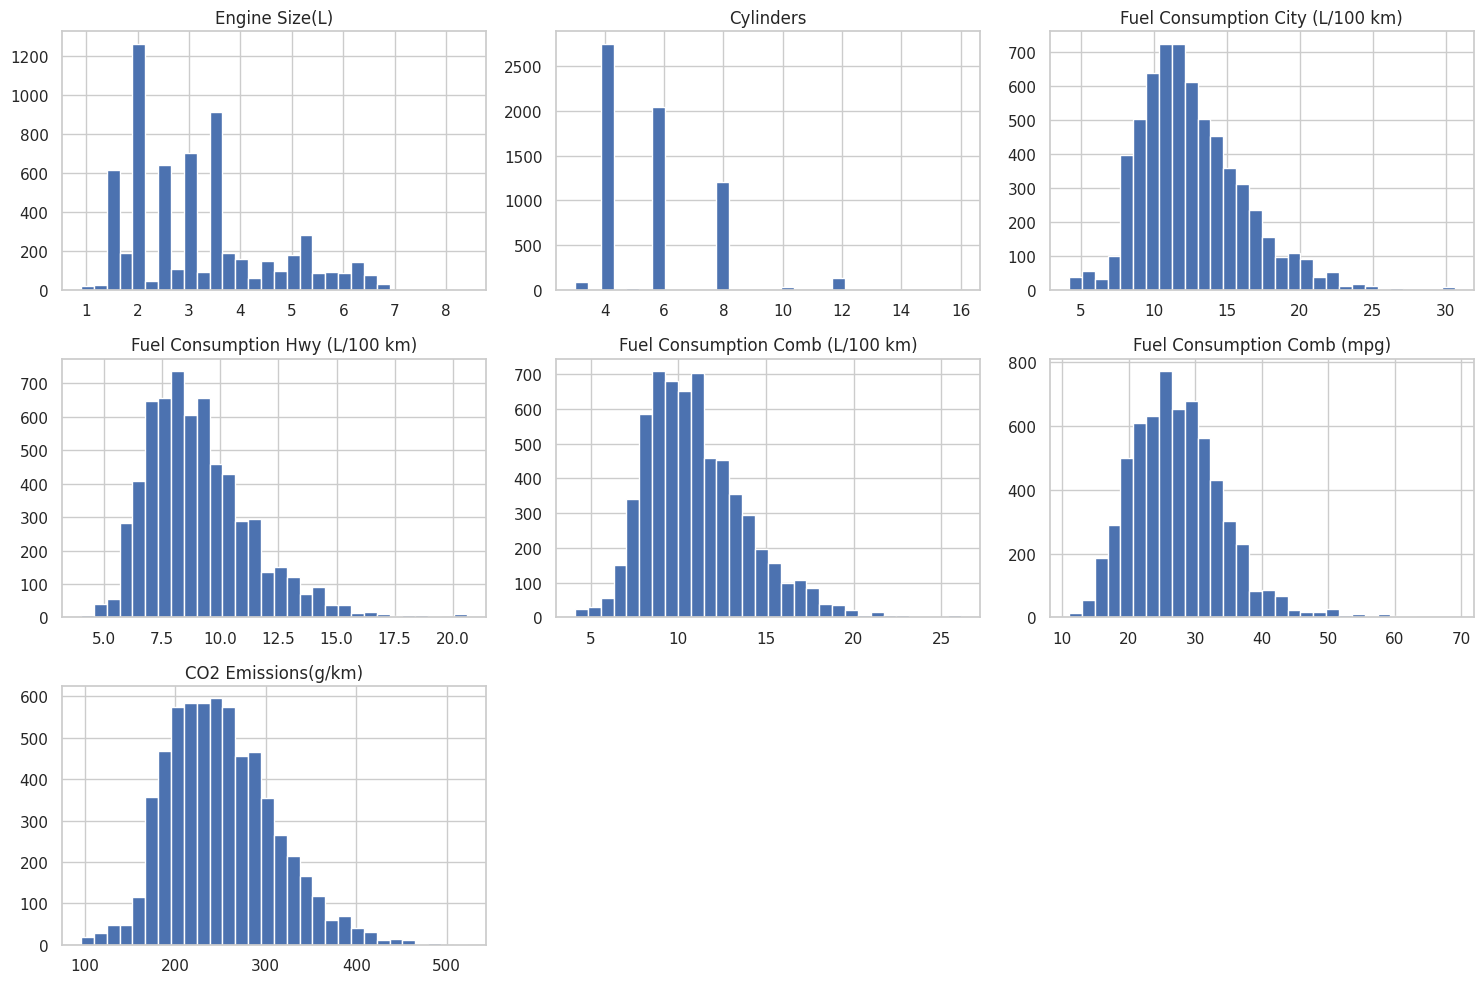

In [ ]:
df.hist(bins=30, figsize=(15, 10))
plt.tight_layout()
plt.show()

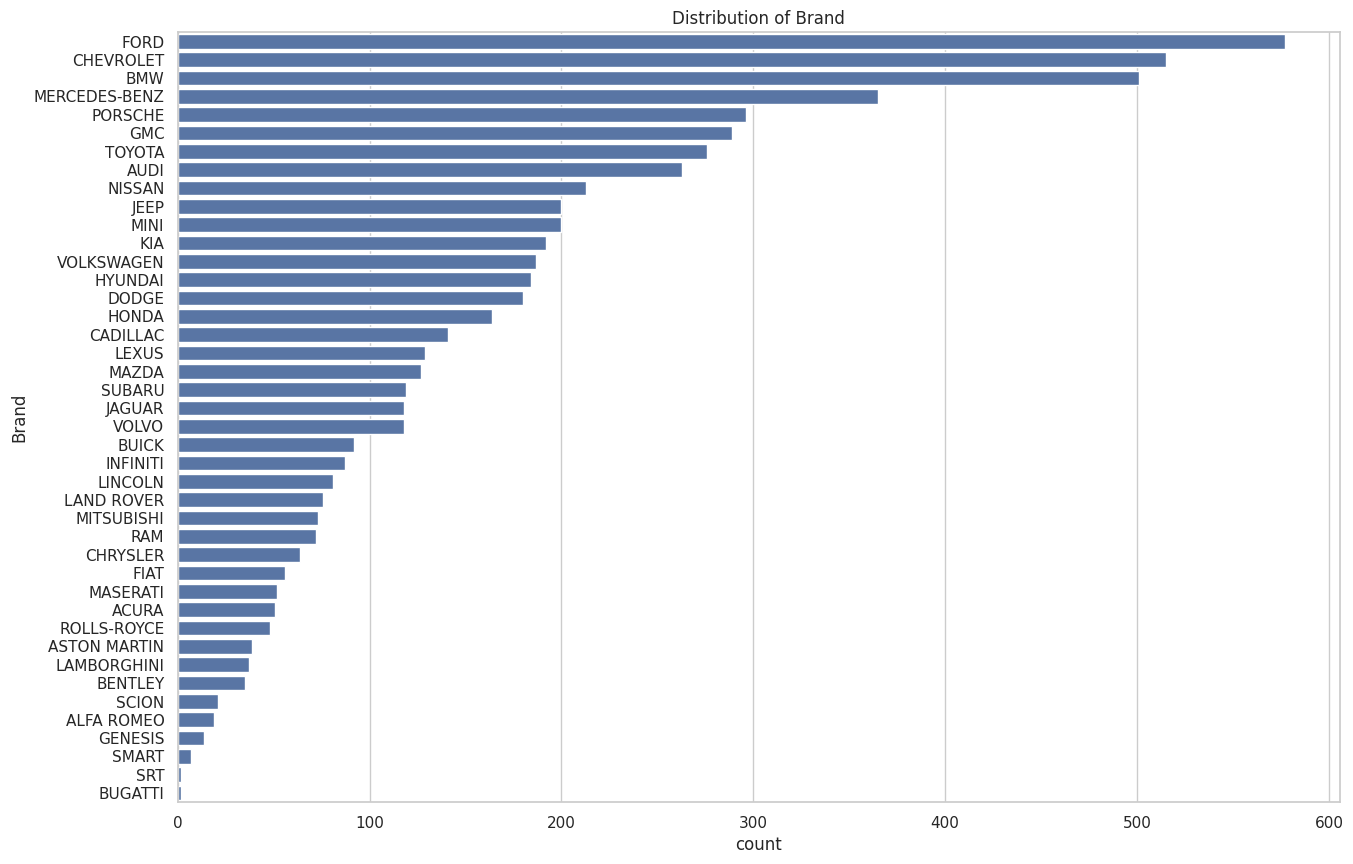

In [ ]:
plt.figure(figsize=(15, 10))
sns.countplot(y='Brand', data=df, order=df['Brand'].value_counts().index)
plt.title('Distribution of Brand')
plt.show()




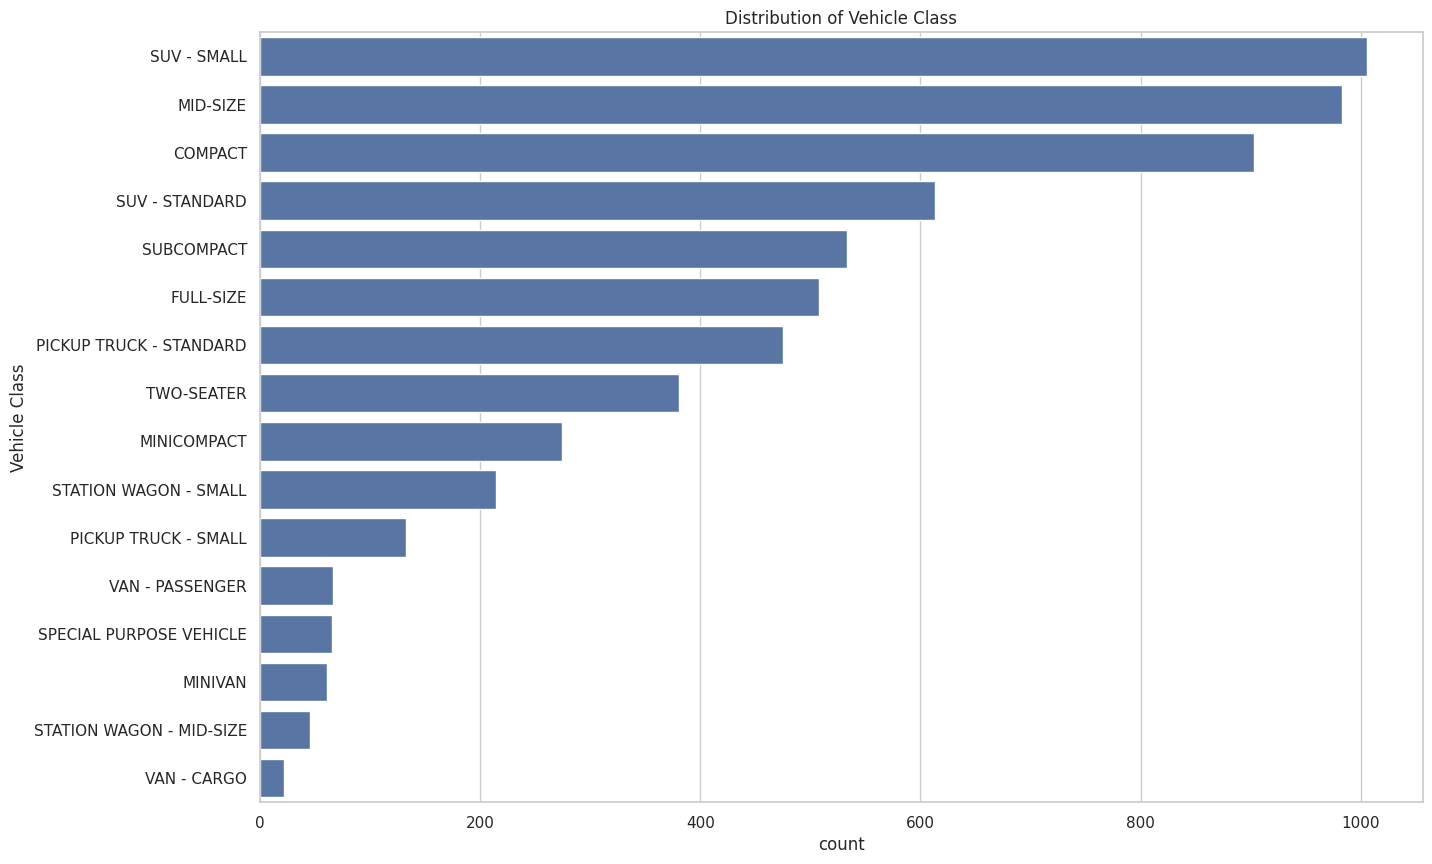

In [ ]:
plt.figure(figsize=(15, 10))
sns.countplot(y='Vehicle Class', data=df, order=df['Vehicle Class'].value_counts().index)
plt.title('Distribution of Vehicle Class')
plt.show()

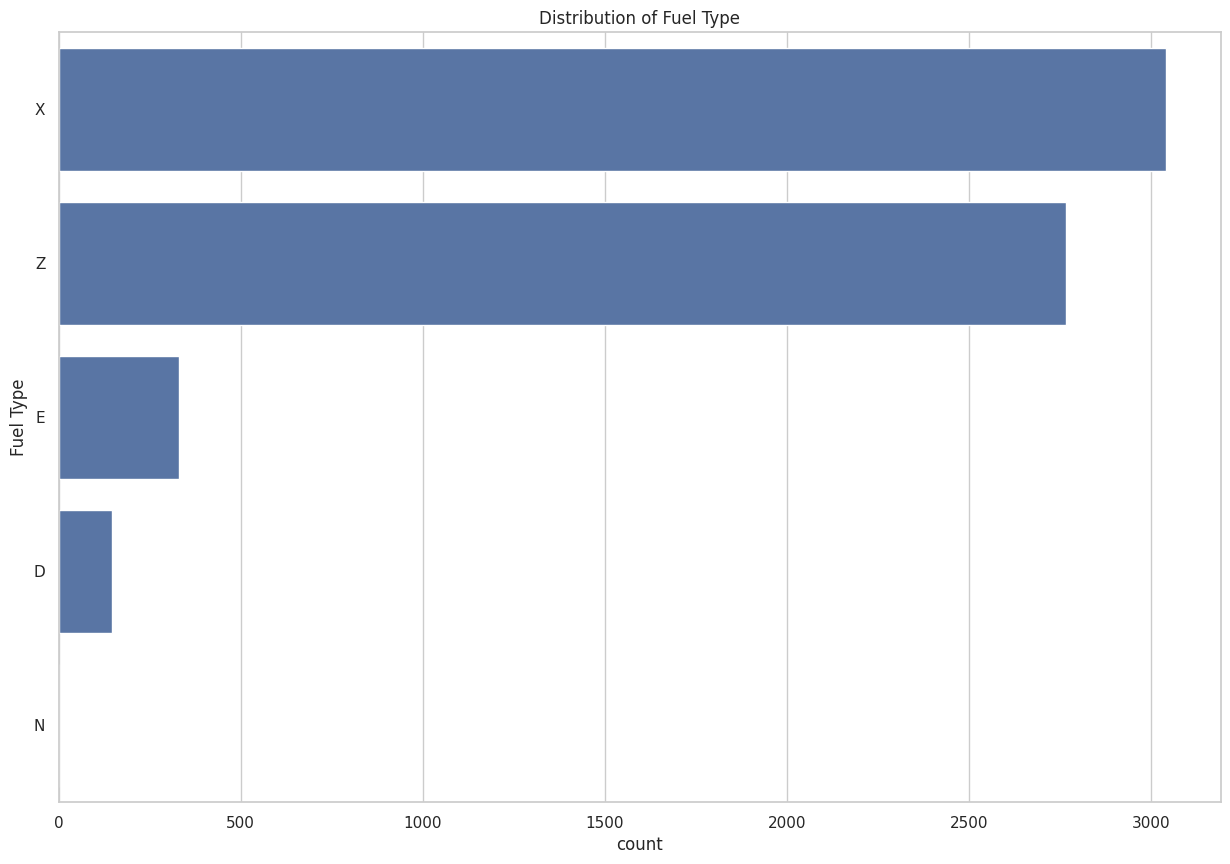

In [ ]:
plt.figure(figsize=(15, 10))
sns.countplot(y='Fuel Type', data=df, order=df['Fuel Type'].value_counts().index)
plt.title('Distribution of Fuel Type')
plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6282 entries, 0 to 7384
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Brand                             6282 non-null   object 
 1   Model                             6282 non-null   object 
 2   Vehicle Class                     6282 non-null   object 
 3   Engine Size(L)                    6282 non-null   float64
 4   Cylinders                         6282 non-null   int64  
 5   Transmission                      6282 non-null   object 
 6   Fuel Type                         6282 non-null   object 
 7   Fuel Consumption City (L/100 km)  6282 non-null   float64
 8   Fuel Consumption Hwy (L/100 km)   6282 non-null   float64
 9   Fuel Consumption Comb (L/100 km)  6282 non-null   float64
 10  Fuel Consumption Comb (mpg)       6282 non-null   int64  
 11  CO2 Emissions(g/km)               6282 non-null   int64  
dtypes: float64(

/tmp/ipykernel_935/2333428439.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_models, x="Engine Size(L)", y="Model", palette="viridis")


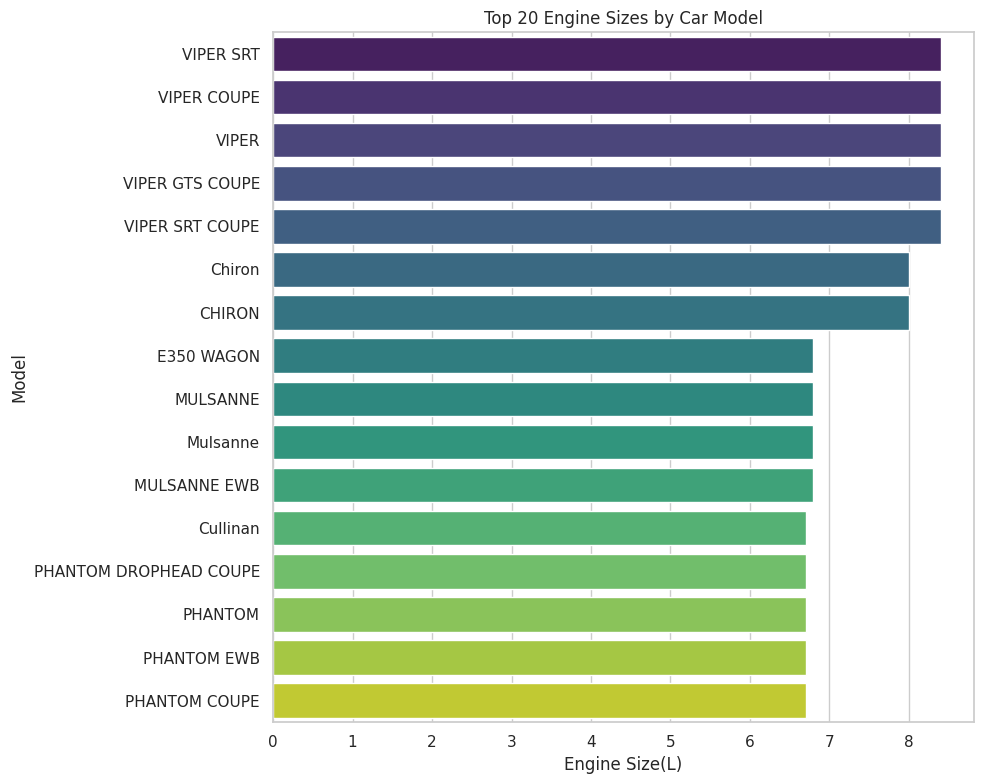

In [ ]:
# Filter or sort for the Top 20 models to keep it clean
top_models = df.sort_values(by="Engine Size(L)", ascending=False).head(20)

plt.figure(figsize=(10, 8))
# Swap x and y to make it horizontal
sns.barplot(data=top_models, x="Engine Size(L)", y="Model", palette="viridis")

plt.title("Top 20 Engine Sizes by Car Model")
plt.tight_layout()
plt.show()

/tmp/ipykernel_935/1794199352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


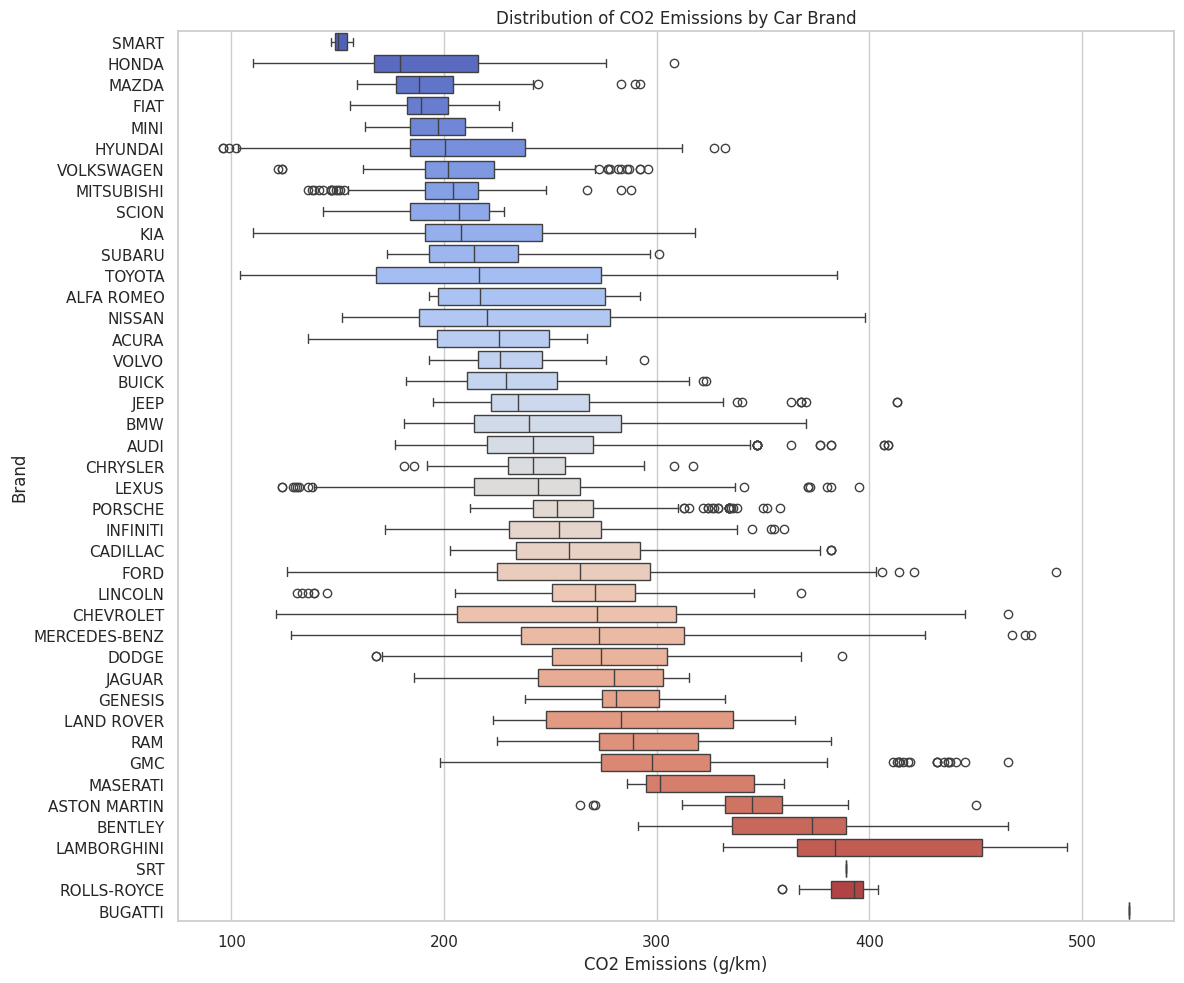

In [ ]:
brand_order = df.groupby("Brand")["CO2 Emissions(g/km)"].median().sort_values().index
plt.figure(figsize=(12, 10))  # Ample height for brand names
sns.boxplot(
    data=df,
    y="Brand",                      # Put Brand on Y-axis for horizontal display
    x="CO2 Emissions(g/km)",
    order=brand_order,
    palette="coolwarm"
)
plt.title("Distribution of CO2 Emissions by Car Brand")
plt.xlabel("CO2 Emissions (g/km)")
plt.tight_layout()
plt.show()

/tmp/ipykernel_935/1551729116.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


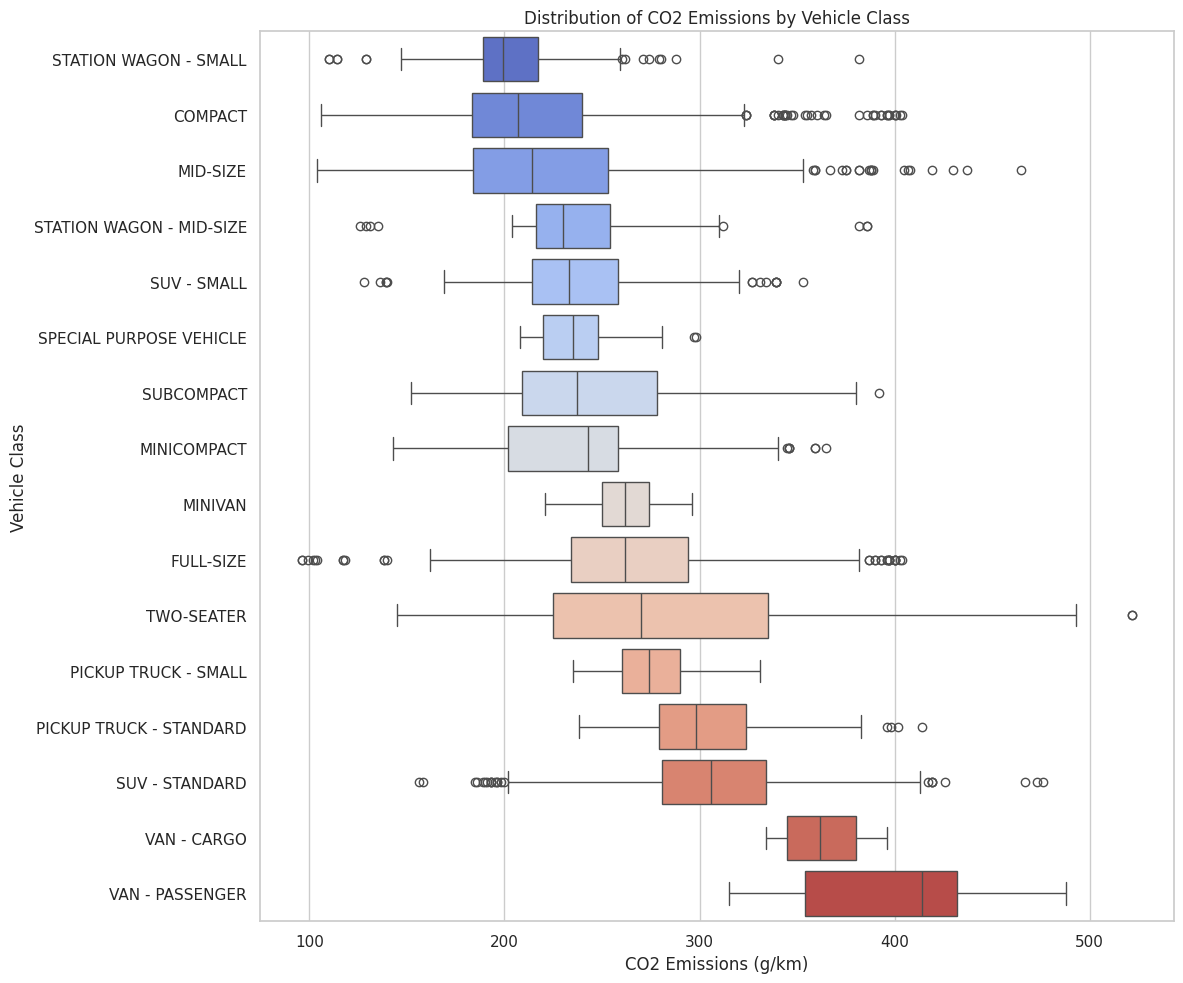

In [ ]:
sorted_vehicle_class = df.groupby("Vehicle Class")["CO2 Emissions(g/km)"].median().sort_values().index
plt.figure(figsize=(12, 10))  # Ample height for brand names
sns.boxplot(
    data=df,
    y="Vehicle Class",
    x="CO2 Emissions(g/km)",
    order=sorted_vehicle_class,
    palette="coolwarm"
)
plt.title("Distribution of CO2 Emissions by Vehicle Class")
plt.xlabel("CO2 Emissions (g/km)")
plt.tight_layout()
plt.show()

/tmp/ipykernel_935/3197768902.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Transmission_Group'] = df['Transmission'].str[:2]
/tmp/ipykernel_935/3197768902.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="Transmission_Group", y="CO2 Emissions(g/km)", palette="muted")


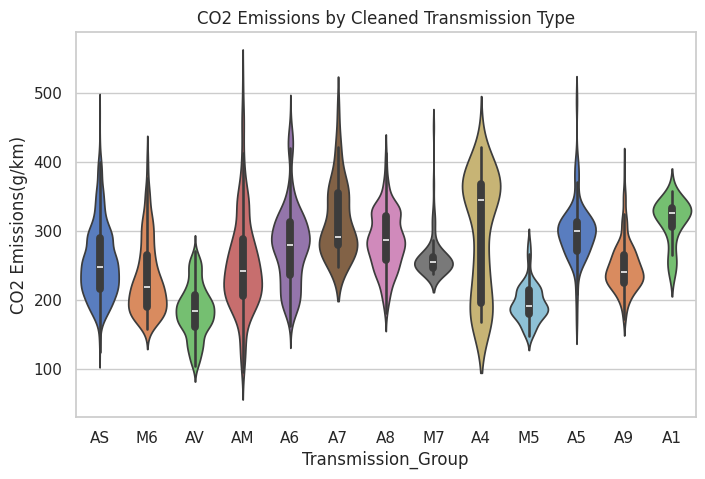

In [ ]:
df['Transmission_Group'] = df['Transmission'].str[:2]
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="Transmission_Group", y="CO2 Emissions(g/km)", palette="muted")
plt.title("CO2 Emissions by Cleaned Transmission Type")
plt.show()


In [ ]:
df["Transmission_Group"]

,Transmission_Group
0,AS
1,M6
2,AV
3,AS
4,AS
...,...
7380,AS
7381,AS
7382,AS
7383,AS


#MODEL

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6282 entries, 0 to 7384
Data columns (total 13 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Brand                             6282 non-null   object 
 1   Model                             6282 non-null   object 
 2   Vehicle Class                     6282 non-null   object 
 3   Engine Size(L)                    6282 non-null   float64
 4   Cylinders                         6282 non-null   int64  
 5   Transmission                      6282 non-null   object 
 6   Fuel Type                         6282 non-null   object 
 7   Fuel Consumption City (L/100 km)  6282 non-null   float64
 8   Fuel Consumption Hwy (L/100 km)   6282 non-null   float64
 9   Fuel Consumption Comb (L/100 km)  6282 non-null   float64
 10  Fuel Consumption Comb (mpg)       6282 non-null   int64  
 11  CO2 Emissions(g/km)               6282 non-null   int64  
 12  Transmissio

In [ ]:
# Initialize your encoder
encoder = OneHotEncoder(sparse_output=False)

# 1. Select all the categorical columns you want to encode in a list
columns_to_encode = ["Brand", "Transmission_Group", "Model","Vehicle Class","Transmission","Fuel Type"]

# 2. Fit and transform all selected columns at once
encoded_array = encoder.fit_transform(df[columns_to_encode])

# 3. Optional: Convert the result back into a readable DataFrame with matching column names
encoded_df = pd.DataFrame(
    encoded_array,
    columns=encoder.get_feature_names_out(columns_to_encode)
)

In [ ]:
x = df[['Brand','Model','Vehicle Class','Engine Size(L)','Cylinders','Transmission','Fuel Type','Fuel Consumption City (L/100 km)','Fuel Consumption Hwy (L/100 km)','Fuel Consumption Comb (L/100 km)','Fuel Consumption Comb (mpg)']]#Feature
y = df["CO2 Emissions(g/km)"] #target

In [ ]:
Categorical_Feature = ['Brand','Model','Vehicle Class','Transmission','Fuel Type']
Numeric_Features = ['Engine Size(L)','Cylinders','Fuel Consumption City (L/100 km)','Fuel Consumption Hwy (L/100 km)','Fuel Consumption Comb (L/100 km)','Fuel Consumption Comb (mpg)']

In [ ]:
Preprocessor = ColumnTransformer(
    transformers= [
    ('categorical', OneHotEncoder(drop = 'if_binary',handle_unknown='ignore'), Categorical_Feature),

], remainder ='passthrough'
)

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

In [ ]:
print(x_train.shape)
print(x_test.shape)

(4711, 11)
(1571, 11)


In [ ]:
from scipy.sparse import lil_array
Model = Pipeline(
    steps = [
        ("preprocessor",Preprocessor),
        ("regressor", LinearRegression())
    ]
)

In [ ]:
Model.fit(x_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categorical',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore'),
                                                  ['Brand', 'Model',
                                                   'Vehicle Class',
                                                   'Transmission',
                                                   'Fuel Type'])])),
                ('regressor', LinearRegression())])

In [ ]:
y_pred = Model.predict(x_test)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [ ]:
#Evaluasi matrix
MSE = mean_squared_error(y_test,y_pred)
MAE = mean_absolute_error(y_test,y_pred)
RMSE = np.sqrt(MSE)
R2SCORE = r2_score(y_test,y_pred)

In [ ]:
print("Mean Squared Error : ", MSE) #Mean Square error harus kecil tapi hasilnya gede banget
print("Mean Absolute Error : ", MAE)
print("Root mean of Square : ", RMSE)
print("R2 Score : ", R2SCORE) #R2 Score harus mendekati 1

Mean Squared Error :  37.23149050536251
Mean Absolute Error :  3.617428448907406
Root mean of Square :  6.101761262566941
R2 Score :  0.9897543306434401


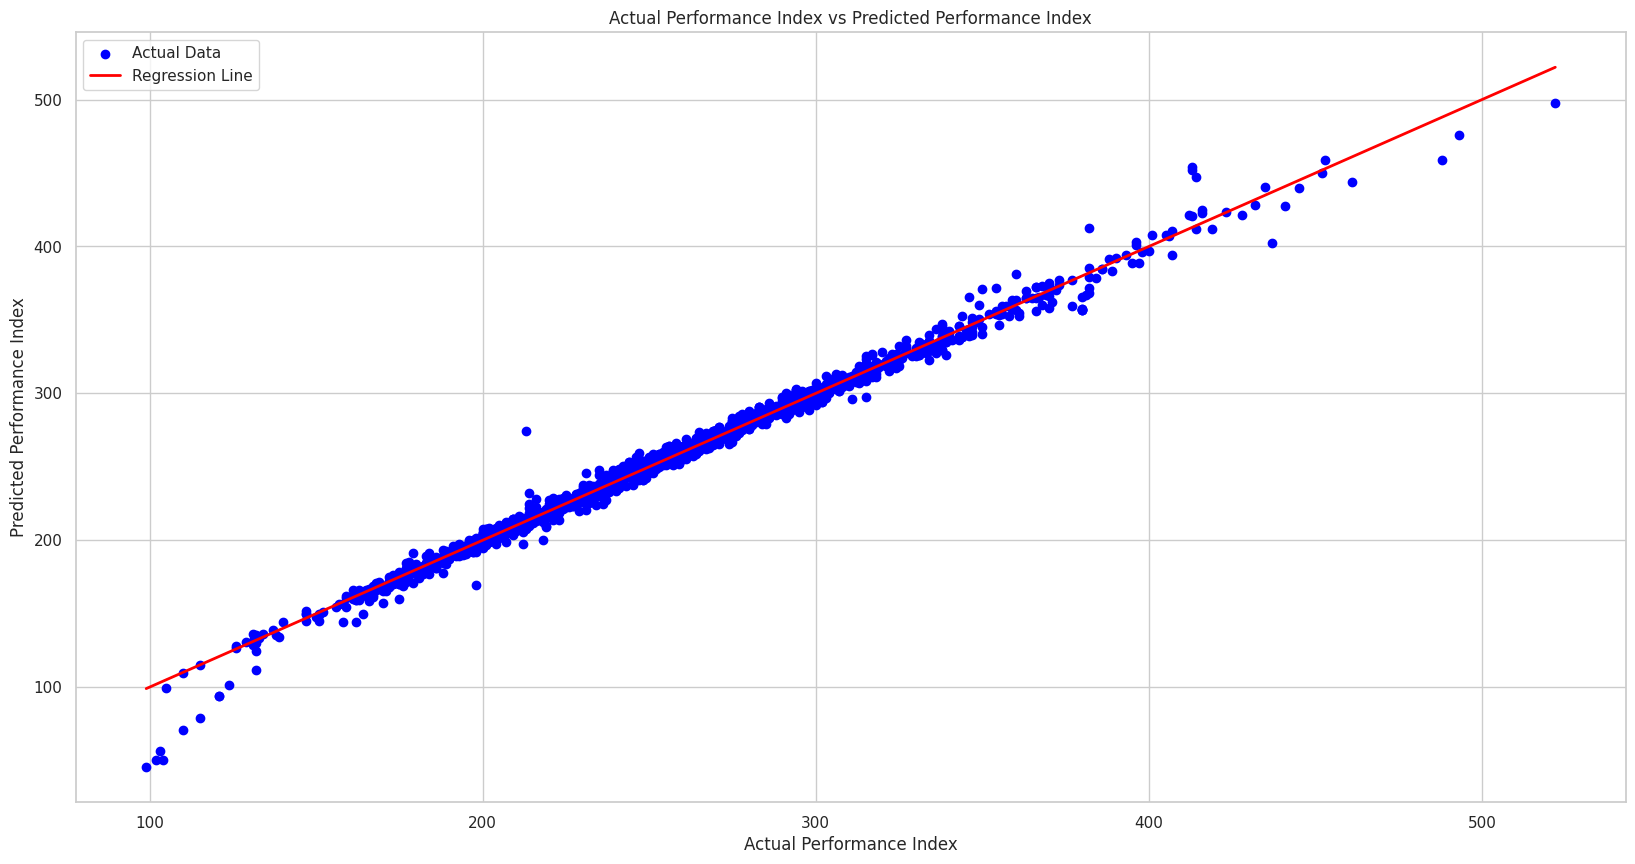

In [ ]:
# Visualisasi Actual vs Regression Line
plt.figure(figsize=(20,10))

plt.scatter(y_test, y_pred, color='blue', label='Actual Data')

plt.plot([y_test.min(),y_test.max()], [y_test.min(),y_test.max()], color='red', linewidth=2, label='Regression Line')

plt.xlabel("Actual Performance Index")
plt.ylabel("Predicted Performance Index")
plt.title('Actual Performance Index vs Predicted Performance Index')
plt.legend()

plt.show()